# Inteligencia Artificial - Tarea 2
**Estudiantes:** Daniel Quintero, Jean Villasmil 

**Profesor:** Tomas Santana  

**Fecha:** 26 de Octubre 2026  

**Dataset seleccionado:** EA FC 27 Player Ratings & Detailed In-Game Stats

**Link:** https://www.kaggle.com/datasets/dahipoomjj/ea-fc-27-player-ratings-and-detailed-in-game-stats

**Fuente del Dataset:** Datos que representan atributos de las cartas, recuperados de registros comunitarios públicos (FUT. GG).

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

# 1. Cargar el dataset real
df = pd.read_csv('fc27_players_database.csv')

# 2. Análisis exploratorio breve y selección de features cuantitativas
# Variables predictoras y objetiva
features = [
    'age', 'face_pace', 'face_shooting', 'face_passing', 
    'face_dribbling', 'face_defending', 'face_physicality', 
    'stat_stamina', 'stat_strength'
]
target = 'overall'

# Limpiar filas con valores nulos en estas columnas
df_clean = df.dropna(subset=features + [target]).copy()

X = df_clean[features].values
y = df_clean[target].values

print(f"Dimensiones originales de X: {X.shape}")

# 3. Separación de conjuntos (Entrenamiento y Prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=60, random_state=42
)

print(f"Muestras de entrenamiento: {X_train.shape[0]}")
print(f"Muestras de prueba: {X_test.shape[0]}")

# 4. Expansion polinómica para disparar la dimensionalidad y provocar sobreajuste
# Con degree=3
poly = PolynomialFeatures(degree=3, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print(f"Dimensiones de X tras PolynomialFeatures (grado 3): {X_train_poly.shape}")

# 5. Entrenar el modelo de Regresión Lineal de Scikit-Learn
lr = LinearRegression()
lr.fit(X_train_poly, y_train)

# 6. Calcular predicciones y métricas RMSE
y_pred_train = lr.predict(X_train_poly)
y_pred_test = lr.predict(X_test_poly)

rmse_train = root_mean_squared_error(y_train, y_pred_train)
rmse_test = root_mean_squared_error(y_test, y_pred_test)

print("\n--- RESULTADOS DEL PUNTO 1 (SOBREAJUSTE) ---")
print(f"RMSE de Entrenamiento: {rmse_train:.4f}")
print(f"RMSE de Prueba:        {rmse_test:.4f}")

Dimensiones originales de X: (8860, 9)
Muestras de entrenamiento: 60
Muestras de prueba: 8800
Dimensiones de X tras PolynomialFeatures (grado 3): (60, 219)

--- RESULTADOS DEL PUNTO 1 (SOBREAJUSTE) ---
RMSE de Entrenamiento: 0.0000
RMSE de Prueba:        6.0298


## Verificación rápida de my_ridge.py

In [3]:
from my_ridge import MyRidge

model = MyRidge(alpha=1.0)
model.fit(X_train_poly, y_train)

preds = model.predict(X_test_poly)
print("Coeficientes (primeros 5):", model.coef_[:5])
print("Intercepto:", model.intercept_)
print("R2 Score (Entrenamiento):", model.score(X_train_poly, y_train))
print("RMSE (Prueba):", model.rmse(X_test_poly, y_test))

Coeficientes (primeros 5): [-4.89880829e-07 -5.19711567e-07  1.02937604e-07  5.68122048e-07
  1.80470903e-08]
Intercepto: 57.78070478160087
R2 Score (Entrenamiento): -4.698076431979101
RMSE (Prueba): 15.7572950167875


## Estandarización y Validación de $\alpha$

Mejor Alpha encontrado: 1.2068
Mejor RMSE de Prueba con Ridge: 2.2578


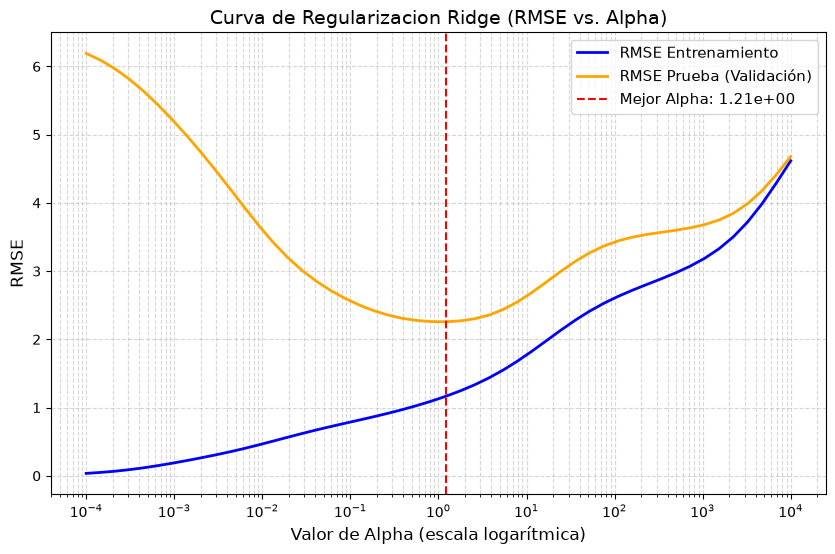

In [4]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# 1. Estandarizar las features polinómicas con StandardScaler (solo fit con train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

# 2. Definir la grilla de valores para alpha (A) en escala logarítmica
alphas = np.logspace(-4, 4, 50)

train_rmse_list = []
test_rmse_list = []

# 3. Evaluar MyRidge para cada alpha en la grilla
for a in alphas:
    # Instanciar y ajustar MyRidge con los datos estandarizados
    ridge_model = MyRidge(alpha=a)
    ridge_model.fit(X_train_scaled, y_train)
    
    # Calcular RMSE en train y test
    train_rmse_list.append(ridge_model.rmse(X_train_scaled, y_train))
    test_rmse_list.append(ridge_model.rmse(X_test_scaled, y_test))

# Encontrar el mejor alpha basado en el menor RMSE de prueba (o validación)
best_idx = np.argmin(test_rmse_list)
best_alpha = alphas[best_idx]
best_rmse = test_rmse_list[best_idx]

print(f"Mejor Alpha encontrado: {best_alpha:.4f}")
print(f"Mejor RMSE de Prueba con Ridge: {best_rmse:.4f}")

# 4. Graficar el RMSE de entrenamiento y prueba en función de Alpha (escala logarítmica)
plt.figure(figsize=(10, 6))
plt.plot(alphas, train_rmse_list, label='RMSE Entrenamiento', color='blue', linewidth=2)
plt.plot(alphas, test_rmse_list, label='RMSE Prueba (Validación)', color='orange', linewidth=2)
plt.axvline(best_alpha, color='red', linestyle='--', label=f'Mejor Alpha: {best_alpha:.2e}')
plt.xscale('log')
plt.xlabel('Valor de Alpha (escala logarítmica)', fontsize=12)
plt.ylabel('RMSE', fontsize=12)
plt.title('Curva de Regularizacion Ridge (RMSE vs. Alpha)', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

## Verificación con Scikit-Learn

In [5]:
from sklearn.linear_model import Ridge

# Probar con el mejor alpha encontrado
alpha_test = best_alpha

# 1. Con features estandarizadas
model_my = MyRidge(alpha=alpha_test).fit(X_train_scaled, y_train)
model_sk = Ridge(alpha=alpha_test).fit(X_train_scaled, y_train)

print("--- VERIFICACIÓN CON SKLEARN (Estandarizado) ---")
print("Coeficientes coinciden:", np.allclose(model_my.coef_, model_sk.coef_))
print("Intercepto coincide:", np.allclose(model_my.intercept_, model_sk.intercept_))
print("R2 coincide:", np.allclose(model_my.score(X_train_scaled, y_train), model_sk.score(X_train_scaled, y_train)))
print("RMSE coincide:", np.allclose(model_my.rmse(X_train_scaled, y_train), np.sqrt(np.mean((y_train - model_sk.predict(X_train_scaled))**2))))

# 2. Ajustar con MyRidge sin estandarizar
model_my_raw = MyRidge(alpha=alpha_test).fit(X_train_poly, y_train)
model_sk_raw = Ridge(alpha=alpha_test).fit(X_train_poly, y_train)

print("\n--- VERIFICACIÓN CON SKLEARN (Sin Estandarizar) ---")
print("Coeficientes coinciden:", np.allclose(model_my_raw.coef_, model_sk_raw.coef_))
print("Intercepto coincide:", np.allclose(model_my_raw.intercept_, model_sk_raw.intercept_))
print("R2 coincide:", np.allclose(model_my_raw.score(X_train_poly, y_train), model_sk_raw.score(X_train_poly, y_train)))
print("RMSE coincide:", np.allclose(model_my_raw.rmse(X_train_poly, y_train), np.sqrt(np.mean((y_train - model_sk_raw.predict(X_train_poly))**2))))

--- VERIFICACIÓN CON SKLEARN (Estandarizado) ---
Coeficientes coinciden: True
Intercepto coincide: True
R2 coincide: True
RMSE coincide: True

--- VERIFICACIÓN CON SKLEARN (Sin Estandarizar) ---
Coeficientes coinciden: False
Intercepto coincide: False
R2 coincide: False
RMSE coincide: False


## Ridge vs. Lasso

c:\Users\echoe\OneDrive\Desktop\Tarea1-IA\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.341625e+00, tolerance: 1.754e-01
  model = cd_fast.enet_coordinate_descent(
c:\Users\echoe\OneDrive\Desktop\Tarea1-IA\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.150509e+00, tolerance: 1.836e-01
  model = cd_fast.enet_coordinate_descent(
c:\Users\echoe\OneDrive\Desktop\Tarea1-IA\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the featu

Mejor Alpha para Ridge: 1.2068
Mejor Alpha para Lasso: 0.0409

--- TABLA COMPARATIVA DE COEFICIENTES (Primeras 10 features) ---
 Feature_Index   MyRidge  Ridge_sklearn  Lasso_sklearn
             0 -0.305489      -0.305489      -0.000000
             1 -0.207547      -0.207547      -0.000000
             2 -0.229687      -0.229687      -0.000000
             3  0.615131       0.615131       1.641514
             4  0.052227       0.052227      -0.000000
             5  0.701314       0.701314       0.007637
             6  0.095716       0.095716       0.000000
             7  0.373680       0.373680       0.000000
             8 -0.032130      -0.032130       0.000000
             9 -0.040951      -0.040951      -0.000000

Coeficientes exactamente en cero en Lasso: 205 de 219
Coeficientes exactamente en cero en Ridge: 0 de 219

RMSE de Prueba - Ridge: 2.2578
RMSE de Prueba - Lasso: 2.2927


c:\Users\echoe\OneDrive\Desktop\Tarea1-IA\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.382358e+00, tolerance: 2.333e-01
  model = cd_fast.enet_coordinate_descent(
c:\Users\echoe\OneDrive\Desktop\Tarea1-IA\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.690794e+00, tolerance: 2.333e-01
  model = cd_fast.enet_coordinate_descent(
c:\Users\echoe\OneDrive\Desktop\Tarea1-IA\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the featu

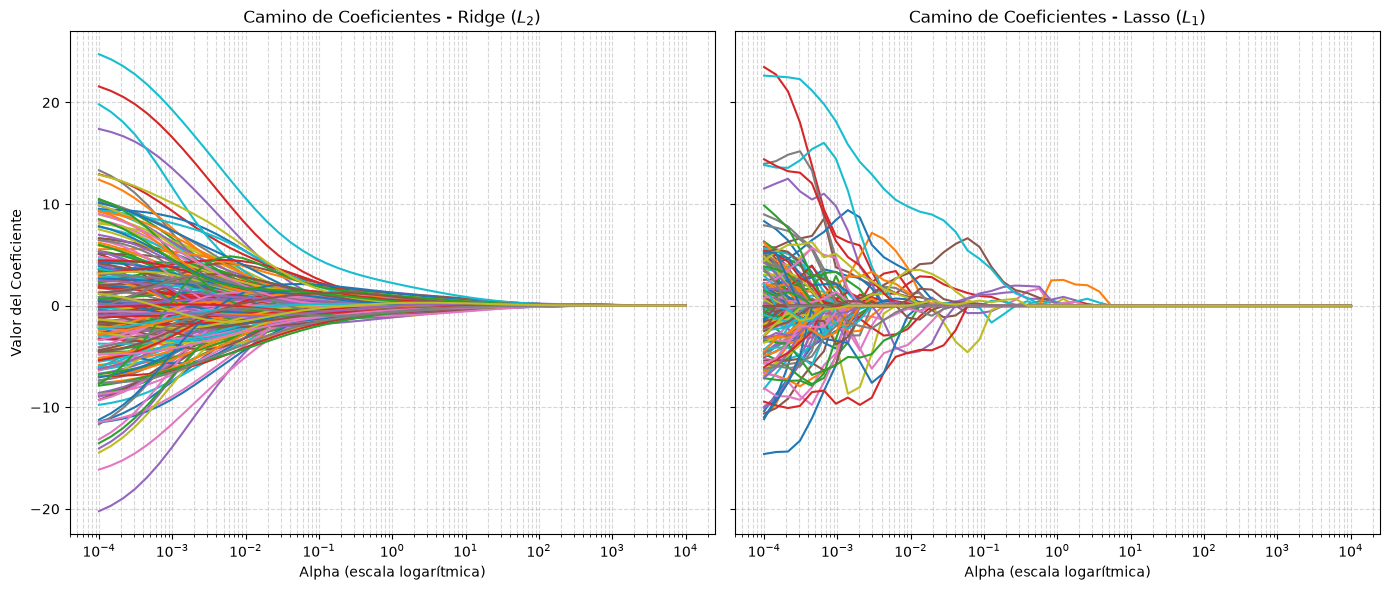

In [8]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV

# 1. Definir la grilla de valores para alpha
alphas = np.logspace(-4, 4, 50)

# 2. Encontrar el mejor alpha para Ridge usando GridSearchCV
ridge_gcv = GridSearchCV(Ridge(), {'alpha': alphas}, cv=5, scoring='neg_root_mean_squared_error')
ridge_gcv.fit(X_train_scaled, y_train)
best_ridge_alpha = ridge_gcv.best_params_['alpha']

# 3. Encontrar el mejor alpha para Lasso usando GridSearchCV (aumentamos max_iter para evitar advertencias)
lasso_gcv = GridSearchCV(Lasso(max_iter=20000), {'alpha': alphas}, cv=5, scoring='neg_root_mean_squared_error')
lasso_gcv.fit(X_train_scaled, y_train)
best_lasso_alpha = lasso_gcv.best_params_['alpha']

print(f"Mejor Alpha para Ridge: {best_ridge_alpha:.4f}")
print(f"Mejor Alpha para Lasso: {best_lasso_alpha:.4f}")

# Entrenar los modelos finales con sus respectivos mejores alphas
ridge_final = Ridge(alpha=best_ridge_alpha).fit(X_train_scaled, y_train)
lasso_final = Lasso(alpha=best_lasso_alpha, max_iter=20000).fit(X_train_scaled, y_train)
my_ridge_final = MyRidge(alpha=best_ridge_alpha).fit(X_train_scaled, y_train)


# 4. Presentar la tabla comparativa de coeficientes lado a lado
coef_df = pd.DataFrame({
    'Feature_Index': range(len(ridge_final.coef_)),
    'MyRidge': my_ridge_final.coef_,
    'Ridge_sklearn': ridge_final.coef_,
    'Lasso_sklearn': lasso_final.coef_
})

print("\n--- TABLA COMPARATIVA DE COEFICIENTES (Primeras 10 features) ---")
print(coef_df.head(10).to_string(index=False))

# 5. Reportar cuántos coeficientes lleva Lasso a cero exacto
zero_lasso_count = np.sum(lasso_final.coef_ == 0)
zero_ridge_count = np.sum(ridge_final.coef_ == 0)
print(f"\nCoeficientes exactamente en cero en Lasso: {zero_lasso_count} de {len(lasso_final.coef_)}")
print(f"Coeficientes exactamente en cero en Ridge: {zero_ridge_count} de {len(ridge_final.coef_)}")

# 6. Comparar el RMSE de prueba de ambos modelos
rmse_test_ridge = root_mean_squared_error(y_test, ridge_final.predict(X_test_scaled))
rmse_test_lasso = root_mean_squared_error(y_test, lasso_final.predict(X_test_scaled))

print(f"\nRMSE de Prueba - Ridge: {rmse_test_ridge:.4f}")
print(f"RMSE de Prueba - Lasso: {rmse_test_lasso:.4f}")

# 7. Graficar los caminos de coeficientes (Coefficient Paths)
ridge_coefs = []
lasso_coefs = []

for a in alphas:
    r = Ridge(alpha=a).fit(X_train_scaled, y_train)
    l = Lasso(alpha=a, max_iter=20000).fit(X_train_scaled, y_train)
    ridge_coefs.append(r.coef_)
    lasso_coefs.append(l.coef_)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Gráfica Ridge
axes[0].plot(alphas, ridge_coefs)
axes[0].set_xscale('log')
axes[0].set_title('Camino de Coeficientes - Ridge ($L_2$)')
axes[0].set_xlabel('Alpha (escala logarítmica)')
axes[0].set_ylabel('Valor del Coeficiente')
axes[0].grid(True, which="both", ls="--", alpha=0.5)

# Gráfica Lasso
axes[1].plot(alphas, lasso_coefs)
axes[1].set_xscale('log')
axes[1].set_title('Camino de Coeficientes - Lasso ($L_1$)')
axes[1].set_xlabel('Alpha (escala logarítmica)')
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

## ¿Por qué Lasso hace cero los coeficientes y Ridge no?

- **Ridge (Norma $L_2$ - Penalización cuadrática):** Su región de restricciones tiene la forma de un círculo o esfera (contornos continuos y suaves). Cuando las curvas de nivel de la función de costo se expanden e intersectan esta restricción, el punto de contacto casi nunca cae sobre los ejes coordenados exactos. Por lo tanto, reduce los coeficientes haciéndolos muy cercanos a cero, pero nunca exactamente cero.

- **Lasso (Norma $L_1$ - Penalización absoluta):** Su región de restricciones tiene la forma de un rombo o diamante con esquinas afiladas sobre los ejes coordenados. Debido a esta geometría con vértices, es altamente probable que las curvas de nivel del error intersecten la restricción justamente en una de esas esquinas (donde uno de los coeficientes es exactamente cero), cumpliendo una función de selección automática de variables. 